In [ ]:
import os
import re
import numpy as np
import pandas as pd
import tifffile
from glob import glob

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import tifffile
from glob import glob
import os
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.ndimage as ndi
from scipy.stats import ttest_ind, spearmanr
from tqdm import tqdm

In [ ]:
# Assign directories
masked_csv_path = r"C:\Users\jvill\Downloads\jorge_kidney_data_annotated_yang\jorge_kidney_data_annotated_yang\sam_outputs-no-sm\sam_masked_summary.csv"
metadata_path = r"C:\Users\jvill\Downloads\jorge_kidney_data_annotated_yang\jorge_kidney_data_annotated_yang\instance_counts.xlsx"

masked_csv_df = pd.read_csv(masked_csv_path)
metadata_df = pd.read_excel(metadata_path)

joined_df = pd.merge(metadata_df, masked_csv_df,  on=['Image_Name', 'Unit', 'Image Index'], how="inner")
joined_path = os.path.join(os.path.dirname(metadata_path), "masked_data-3.csv")
joined_df.to_csv(joined_path)

C:\Users\jvill\AppData\Local\Temp\ipykernel_30992\3246762853.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'] = pd.Categorical(df['Group'], categories=desired_order, ordered=True)


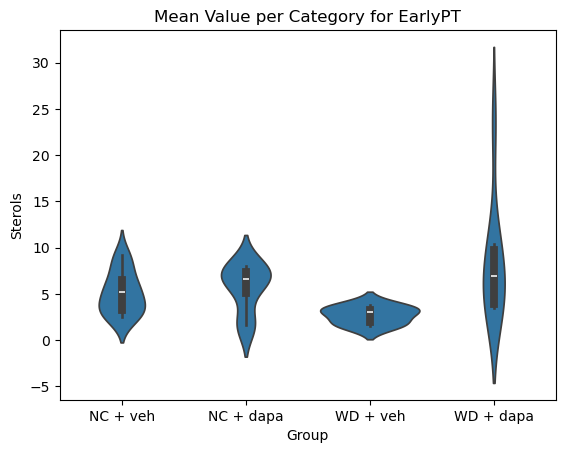

C:\Users\jvill\AppData\Local\Temp\ipykernel_30992\3246762853.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'] = pd.Categorical(df['Group'], categories=desired_order, ordered=True)


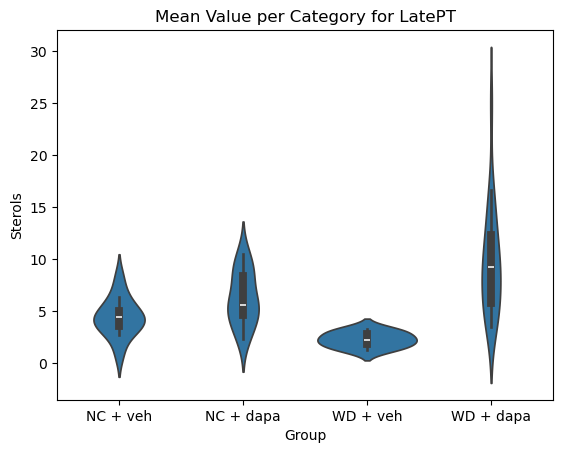

C:\Users\jvill\AppData\Local\Temp\ipykernel_30992\3246762853.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'] = pd.Categorical(df['Group'], categories=desired_order, ordered=True)


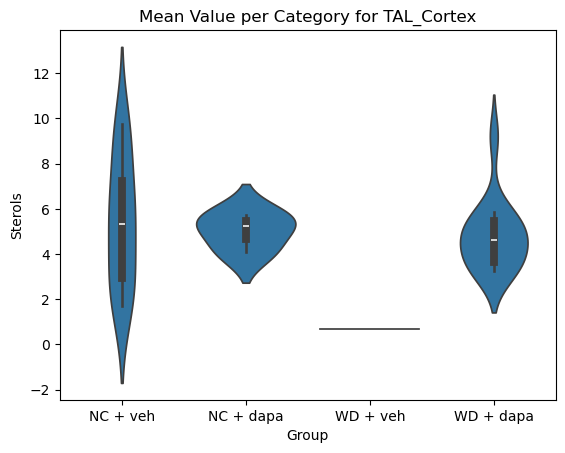

C:\Users\jvill\AppData\Local\Temp\ipykernel_30992\3246762853.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'] = pd.Categorical(df['Group'], categories=desired_order, ordered=True)


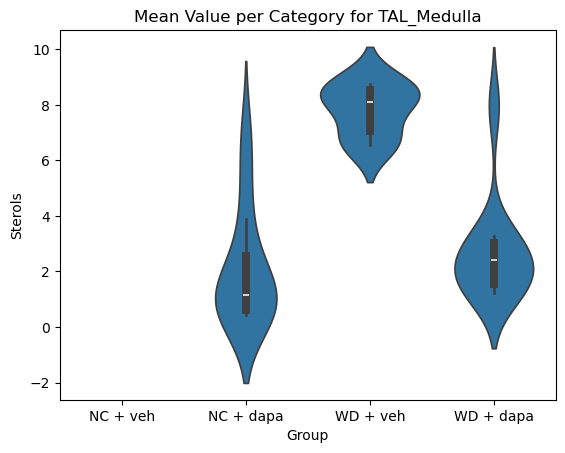

In [32]:
molecule_list = ['Sterols', 'Phospholipids', 'Glycerols', 'Sphingolipids', 'Fatty Acids', 'Carnitines']

for unit in joined_df['Unit'].unique():
    df = joined_df[joined_df['Unit'] == unit]
    # agg_df = df.groupby('Group')[molecule_list].mean().reset_index()

    desired_order = ['NC + veh', 'NC + dapa', 'WD + veh', 'WD + dapa']  # custom order
    df['Group'] = pd.Categorical(df['Group'], categories=desired_order, ordered=True)
    # agg_df['Group'] = pd.Categorical(agg_df['Group'], categories=desired_order, ordered=True)
    # agg_df = agg_df.sort_values('Group')

    # Create bar plot
    sns.violinplot(data=df, x='Group', y='Sterols')
    plt.title(f"Mean Value per Category for {unit}")
    plt.show()

In [29]:
df

,Image_Name,Unit,Image Index,Nuclei_count,Group Number,Group,Instance_Label,centroid_x,centroid_y,n_pixels,...,Glycerols_Similarity,Sphingolipids,Sphingolipids_Similarity,Fatty Acids,Fatty Acids_Similarity,Carnitines,Carnitines_Similarity,Lipid Droplet Count,Lipid Droplet Majority Molecules,Lipid Droplet Avg Area um2
48,6_1-TAL_Medulla-HSI,TAL_Medulla,1,2,1,NC + dapa,01,175.215927,177.282878,19238,...,0.913184,6.175161,0.934494,0.006269,0.850811,NaN,NaN,NaN,NaN,NaN
49,6_1-TAL_Medulla-HSI,TAL_Medulla,2,2,2,NC + dapa,02,208.910795,357.058121,15313,...,0.907994,0.341297,0.907847,NaN,NaN,0.025597,0.872464,4.0,"['Phospholipids', 'Phospholipids', 'Phospholip...",0.741699
50,6_1-TAL_Medulla-HSI,TAL_Medulla,3,4,3,NC + dapa,03,148.472989,453.357343,14605,...,0.907580,3.482756,0.928369,0.008474,0.867223,0.016948,0.873071,2.0,"['Sterols', 'Sterols']",0.315918
51,6_1-TAL_Medulla-HSI,TAL_Medulla,4,2,4,NC + dapa,04,402.563548,475.678962,9245,...,0.904674,3.477905,0.920510,0.013639,0.851832,0.040917,0.863091,1.0,['Phospholipids'],0.439453
52,6_1-TAL_Medulla-HSI,TAL_Medulla,5,3,5,NC + dapa,05,345.105864,368.161496,17598,...,0.913685,1.695320,0.916391,0.055715,0.893218,0.047755,0.871929,5.0,"['Phospholipids', 'Phospholipids', 'Phospholip...",0.807617
53,6_1-TAL_Medulla-HSI,TAL_Medulla,6,2,6,NC + dapa,06,478.249479,424.095417,9600,...,0.895902,0.081954,0.892354,0.016391,0.851832,0.016391,0.857079,1.0,['Phospholipids'],0.604492
54,6_1-TAL_Medulla-HSI,TAL_Medulla,7,2,7,NC + dapa,07,471.547132,215.972234,11489,...,0.912485,9.242723,0.927731,NaN,NaN,0.011597,0.860521,3.0,"['Sterols', 'Sterols', 'Phospholipids']",0.595215
55,6_1-TAL_Medulla-HSI,TAL_Medulla,8,2,8,NC + dapa,08,342.879539,187.009211,22472,...,0.906551,3.880466,0.926392,0.016419,0.891649,0.021893,0.857237,3.0,"['Sterols', 'Glycerols', 'Sterols']",0.512695
56,6_1-TAL_Medulla-HSI,TAL_Medulla,9,2,9,NC + dapa,09,354.225967,54.363398,15666,...,0.854976,0.043425,0.884855,NaN,NaN,0.008685,0.851066,5.0,"['Phospholipids', 'Sterols', 'Phospholipids', ...",0.483398
69,7_1-TAL_Medulla-1-HSI,TAL_Medulla,1,2,10,NC + dapa,01,452.004411,110.278782,11561,...,0.878827,2.366864,0.902304,0.015571,0.868903,0.311429,0.865702,17.0,"['Phospholipids', 'Phospholipids', 'Phospholip...",0.492920


In [ ]:
joined_df['Sterols']

0      5.284153
1      5.522728
2      2.586855
3      2.470131
4      5.916271
         ...   
155    1.384876
156    2.496314
157    1.523623
158    1.704787
159    1.606765
Name: Sterols, Length: 160, dtype: float64